# Range-based volatility test

Can we predict how volatile tomorrow will be, and does news help? The move-size test used the absolute return, which turned out to be too noisy. This uses a less noisy measure of each day's variance, built from prices already in the data:

```text
overnight = (ln(open / previous close))²
intraday  = 0.5 × (ln(high / low))² − (2 ln 2 − 1) × (ln(close / open))²   (Garman–Klass, 1980)
variance  = overnight + intraday
target    = ln(next day's variance)
```

The target has no direction, so it can't say whether the price goes up or down. It can give a likely price range, shown as 95% price bands below.

Models train with MSE on the log, as before. Forecasts are converted back with `exp(forecast + s²/2)`, where `s²` is the fit's mean squared error on its known days, and judged with QLIKE and MSE on the variance scale (Patton, 2011). QLIKE is `actual / forecast − ln(actual / forecast) − 1`, so it depends on the ratio and a few huge days count less than with MSE.

**Baselines:** the train mean (the average variance of earlier days), yesterday's variance, the 5-day and 20-day averages, and **log-HAR**, a linear regression on the 1, 5 and 22-day averages of the log variance. Log-HAR is the main baseline, and is labelled `HAR` in the tables.

**The questions, fixed before any results.** "Clearly beats" means the QLIKE improvement interval is above zero, and MSE and rank correlation aren't clearly worse.

1. Does log-HAR clearly beat the train mean? If not, news isn't tested on this target.
2. Does a trained model clearly beat log-HAR?
3. Does news clearly beat no news with the same model, and does log-HAR + news beat log-HAR?

All runs use the 6 models from the move-size test, 3 seeds, common dates and standardization. Walk-forward is the main evidence, and 80/10/10 is a second view. The test split stays locked.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.data import NEWS_WITH_FEATURES, NO_NEWS_NO_FEATURES
from benchmarking.range_volatility import (
    add_split_error_variance,
    band_scores,
    compare_news,
    compare_to_har,
    compare_to_train_mean,
    largest_misses,
    price_bands,
    range_intervals,
    rolling_baselines,
    run_range_split,
    run_range_walk_forward,
    to_variance,
)
from benchmarking.result_plots import plot_move_comparisons, plot_move_intervals, plot_price_bands

RESULTS_DIR = Path.cwd().parent / "results"
INTERVAL_METRICS = (("qlike_skill", "QLIKE skill (0 = train mean)"), ("rank_correlation", "Rank correlation with actual variance"))
COMPARISON_METRICS = (
    ("qlike_improvement", 1, "QLIKE improvement"),
    ("mse_improvement", 1e6, "MSE improvement × 1,000,000"),
    ("rank_gain", 1, "Rank correlation gain"),
)

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100, "display.float_format", "{:.4f}".format)


def scale(table):
    """Show tiny variance MSE values multiplied by 1,000,000."""
    columns = [c for c in table.columns if c.startswith("mse")]
    return table.assign(**{column: table[column] * 1e6 for column in columns})

## Training

Log-HAR is fitted once per round and has no randomness. Saved work is skipped.

In [2]:
run_range_walk_forward(RESULTS_DIR / "range_walk_forward_predictions.csv")
run_range_split(RESULTS_DIR / "range_split_predictions.csv")

## Load saved results

Forecasts are converted back to variance. The simple baselines need no training, and only use days before each scored day.

In [3]:
trained = to_variance(pd.read_csv(RESULTS_DIR / "range_walk_forward_predictions.csv"))
walk_forward = pd.concat([trained, rolling_baselines(trained)], ignore_index=True)
validation = to_variance(add_split_error_variance(pd.read_csv(RESULTS_DIR / "range_split_predictions.csv")))

## Walk-forward

### Walk-forward: results with confidence intervals

781 scored days. `qlike_skill` and `oos_r2` are relative to the train mean, so above 0 beats it.

In [4]:
intervals = range_intervals(walk_forward)
intervals.to_csv(RESULTS_DIR / "range_walk_forward_intervals.csv", index=False)
intervals.drop(columns="days").sort_values("qlike_skill", ascending=False)

,track,model,qlike,baseline_qlike,correlation,qlike_skill,qlike_skill_lower,qlike_skill_upper,oos_r2,oos_r2_lower,oos_r2_upper,rank_correlation,rank_correlation_lower,rank_correlation_upper
19,news_with_feature_engineering,HAR + news,0.4581,0.5273,0.1990,0.1312,-0.1234,0.3443,0.0383,-0.0069,0.1521,0.5029,0.3881,0.5839
12,no_news_with_feature_engineering,XGBoost | Stronger,0.4584,0.5273,0.2168,0.1306,-0.0446,0.2868,0.0351,0.0007,0.1360,0.4451,0.3250,0.5354
10,no_news_with_feature_engineering,RNN | Dropout 0.5,0.4609,0.5273,0.2322,0.1259,-0.0255,0.2830,0.0367,0.0014,0.1485,0.4412,0.3217,0.5407
6,no_news_no_feature_engineering,HAR,0.4614,0.5273,0.1955,0.1249,-0.1254,0.3481,0.0372,-0.0084,0.1582,0.5156,0.4000,0.5903
5,no_news_no_feature_engineering,XGBoost | Stronger,0.4623,0.5273,0.2066,0.1232,-0.0428,0.2825,0.0324,0.0005,0.1204,0.4418,0.3217,0.5342
4,no_news_no_feature_engineering,LSTM | Dropout 0.5,0.4634,0.5273,0.2315,0.1211,-0.0831,0.2967,0.0359,-0.0001,0.1381,0.4253,0.2876,0.5253
1,no_news_no_feature_engineering,LSTM,0.4674,0.5273,0.2016,0.1136,-0.1155,0.3134,0.0354,-0.0024,0.1666,0.4747,0.3486,0.5594
25,news_with_feature_engineering_and_tech,XGBoost | Stronger,0.4701,0.5273,0.2072,0.1084,-0.0816,0.2770,0.0289,-0.0026,0.1189,0.4603,0.3447,0.5489
18,news_with_feature_engineering,XGBoost | Stronger,0.4741,0.5273,0.2011,0.1008,-0.0874,0.2765,0.0273,-0.0019,0.1171,0.4500,0.3335,0.5346
7,no_news_with_feature_engineering,RNN,0.4806,0.5273,0.2098,0.0885,-0.1388,0.2928,0.0340,-0.0089,0.1352,0.4927,0.3755,0.5714


### Walk-forward: chart

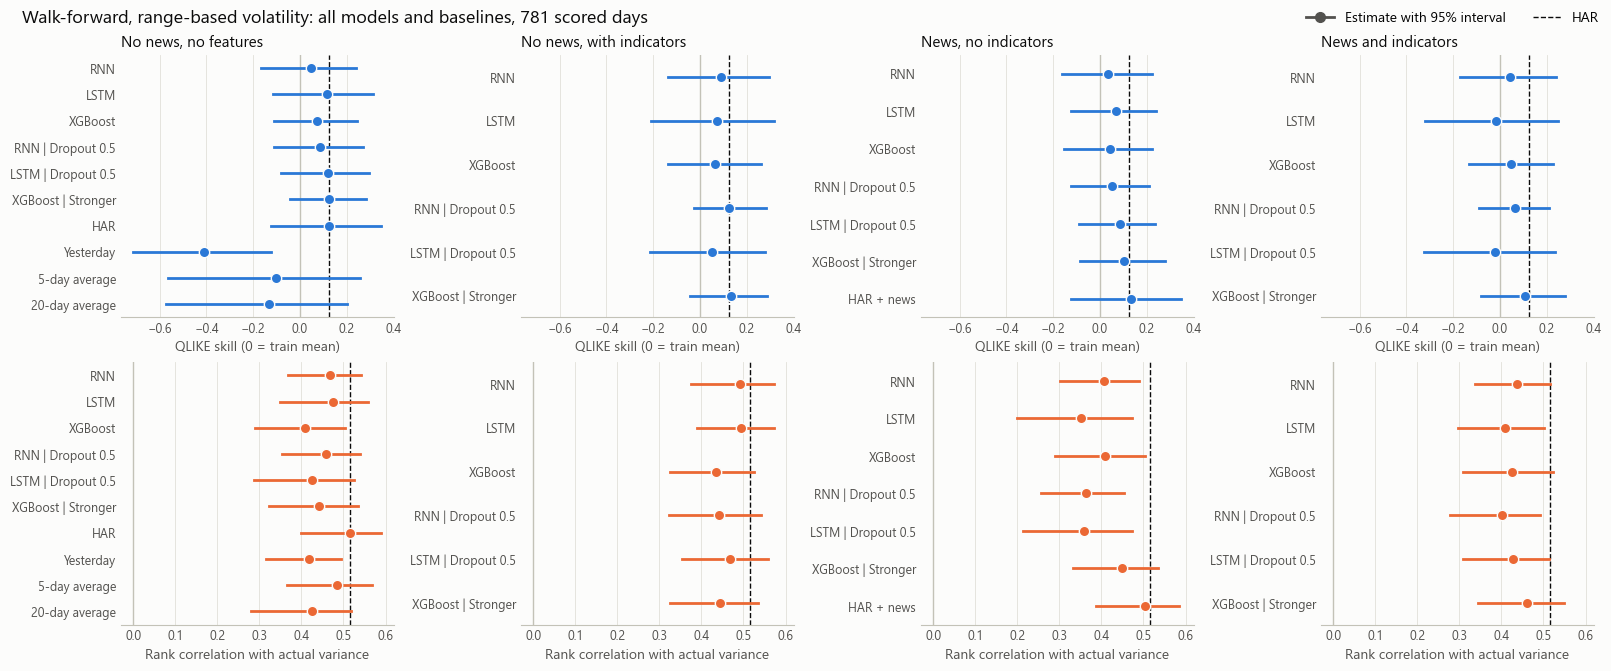

In [5]:
plot_move_intervals(
    intervals,
    title="Walk-forward, range-based volatility: all models and baselines, 781 scored days",
    metrics=INTERVAL_METRICS,
)

## Question 1: does log-HAR beat the train mean?

Every model against the train mean, day by day. Positive differences favor the model. MSE is shown multiplied by 1,000,000.

In [6]:
against_mean = compare_to_train_mean(walk_forward)
against_mean.to_csv(RESULTS_DIR / "range_against_train_mean.csv", index=False)
scale(against_mean).drop(columns="days")

,track,model,qlike_first,qlike_second,rank_first,rank_second,qlike_improvement,qlike_improvement_lower,qlike_improvement_upper,mse_improvement,mse_improvement_lower,mse_improvement_upper,rank_gain,rank_gain_lower,rank_gain_upper
0,no_news_no_feature_engineering,RNN,0.5031,0.5273,0.4671,-0.1631,0.0242,-0.0944,0.1239,0.2113,-0.0897,0.5658,0.6303,0.4027,0.8056
1,no_news_no_feature_engineering,LSTM,0.4674,0.5273,0.4747,-0.1631,0.0599,-0.0634,0.1616,0.2581,-0.0263,0.5915,0.6379,0.3996,0.8275
2,no_news_no_feature_engineering,XGBoost,0.4881,0.5273,0.4075,-0.1631,0.0391,-0.0518,0.1270,0.2093,-0.0138,0.4643,0.5707,0.3545,0.7410
3,no_news_no_feature_engineering,RNN | Dropout 0.5,0.4813,0.5273,0.4595,-0.1631,0.0460,-0.0538,0.1370,0.1998,-0.0389,0.4662,0.6227,0.3951,0.8004
4,no_news_no_feature_engineering,LSTM | Dropout 0.5,0.4634,0.5273,0.4253,-0.1631,0.0638,-0.0393,0.1535,0.2617,0.0059,0.5431,0.5884,0.3553,0.7785
5,no_news_no_feature_engineering,XGBoost | Stronger,0.4623,0.5273,0.4418,-0.1631,0.0650,-0.0219,0.1511,0.2362,0.0064,0.5074,0.6049,0.3768,0.7814
6,no_news_no_feature_engineering,HAR,0.4614,0.5273,0.5156,-0.1631,0.0658,-0.0659,0.1811,0.2715,-0.0786,0.6764,0.6788,0.4279,0.8581
7,no_news_with_feature_engineering,RNN,0.4806,0.5273,0.4927,-0.1631,0.0467,-0.0754,0.1567,0.2482,-0.0749,0.6163,0.6559,0.4177,0.8357
8,no_news_with_feature_engineering,LSTM,0.4898,0.5273,0.4938,-0.1631,0.0375,-0.1235,0.1611,0.2404,-0.0676,0.5866,0.6569,0.4118,0.8410
9,no_news_with_feature_engineering,XGBoost,0.4928,0.5273,0.4352,-0.1631,0.0345,-0.0765,0.1296,0.1941,-0.0400,0.4374,0.5983,0.3846,0.7676


### Question 1: without the 8 most volatile days

A sensitivity check, not part of the fixed rule. It removes the 1% of scored days with the highest actual variance, chosen from the actual values only, so the choice doesn't depend on any model.

In [7]:
spikes = trained.groupby("day")["actual"].first().nlargest(8).index
print("Removed:", ", ".join(spikes.sort_values().strftime("%Y-%m-%d")))
scale(compare_to_train_mean(walk_forward[~walk_forward["day"].isin(spikes)])).drop(columns="days")

Removed: 2022-08-08, 2023-02-23, 2023-05-25, 2024-02-22, 2024-07-31, 2024-08-05, 2025-01-27, 2025-04-07


,track,model,qlike_first,qlike_second,rank_first,rank_second,qlike_improvement,qlike_improvement_lower,qlike_improvement_upper,mse_improvement,mse_improvement_lower,mse_improvement_upper,rank_gain,rank_gain_lower,rank_gain_upper
0,no_news_no_feature_engineering,RNN,0.3225,0.3842,0.4638,-0.1608,0.0617,0.0021,0.1251,0.1121,-0.0147,0.2747,0.6246,0.3970,0.7993
1,no_news_no_feature_engineering,LSTM,0.2903,0.3842,0.4713,-0.1608,0.0939,0.0370,0.1571,0.2149,0.0713,0.4069,0.6320,0.3921,0.8182
2,no_news_no_feature_engineering,XGBoost,0.3281,0.3842,0.4018,-0.1608,0.0561,-0.0050,0.1205,0.1776,0.0589,0.3241,0.5625,0.3473,0.7417
3,no_news_no_feature_engineering,RNN | Dropout 0.5,0.3061,0.3842,0.4559,-0.1608,0.0781,0.0226,0.1372,0.1886,0.0665,0.3398,0.6167,0.3935,0.7929
4,no_news_no_feature_engineering,LSTM | Dropout 0.5,0.2985,0.3842,0.4201,-0.1608,0.0857,0.0322,0.1422,0.2173,0.0979,0.3759,0.5809,0.3486,0.7724
5,no_news_no_feature_engineering,XGBoost | Stronger,0.3084,0.3842,0.4369,-0.1608,0.0758,0.0213,0.1330,0.1806,0.0794,0.2960,0.5976,0.3712,0.7738
6,no_news_no_feature_engineering,HAR,0.2768,0.3842,0.5172,-0.1608,0.1073,0.0509,0.1703,0.2138,0.0622,0.4229,0.6780,0.4342,0.8517
7,no_news_with_feature_engineering,RNN,0.3071,0.3842,0.4895,-0.1608,0.0771,0.0167,0.1430,0.1654,0.0257,0.3481,0.6503,0.4141,0.8236
8,no_news_with_feature_engineering,LSTM,0.2858,0.3842,0.4932,-0.1608,0.0984,0.0409,0.1625,0.2287,0.0921,0.4194,0.6539,0.4102,0.8353
9,no_news_with_feature_engineering,XGBoost,0.3166,0.3842,0.4312,-0.1608,0.0675,0.0072,0.1310,0.1901,0.0718,0.3374,0.5920,0.3815,0.7623


## Question 2: does a trained model beat log-HAR?

### Against log-HAR: table

Positive differences favor the model. MSE is shown multiplied by 1,000,000.

In [8]:
against_har = compare_to_har(walk_forward)
against_har.to_csv(RESULTS_DIR / "range_against_har.csv", index=False)
scale(against_har).drop(columns="days")

,track,model,qlike_first,qlike_second,rank_first,rank_second,qlike_improvement,qlike_improvement_lower,qlike_improvement_upper,mse_improvement,mse_improvement_lower,mse_improvement_upper,rank_gain,rank_gain_lower,rank_gain_upper
0,no_news_no_feature_engineering,RNN,0.5031,0.4614,0.4671,0.5156,-0.0417,-0.0811,-0.0046,-0.0603,-0.1478,0.0301,-0.0485,-0.1051,0.0056
1,no_news_no_feature_engineering,LSTM,0.4674,0.4614,0.4747,0.5156,-0.0059,-0.0379,0.0239,-0.0134,-0.2161,0.1255,-0.0409,-0.0958,0.0083
2,no_news_no_feature_engineering,XGBoost,0.4881,0.4614,0.4075,0.5156,-0.0267,-0.0817,0.0433,-0.0622,-0.2266,0.0792,-0.1081,-0.1777,-0.0365
3,no_news_no_feature_engineering,RNN | Dropout 0.5,0.4813,0.4614,0.4595,0.5156,-0.0198,-0.0601,0.0264,-0.0717,-0.2407,0.0596,-0.0561,-0.1138,0.0007
4,no_news_no_feature_engineering,LSTM | Dropout 0.5,0.4634,0.4614,0.4253,0.5156,-0.0020,-0.0415,0.0445,-0.0098,-0.1559,0.1089,-0.0903,-0.1781,-0.0163
5,no_news_no_feature_engineering,XGBoost | Stronger,0.4623,0.4614,0.4418,0.5156,-0.0009,-0.0470,0.0635,-0.0354,-0.1914,0.1015,-0.0739,-0.1279,-0.0210
6,no_news_with_feature_engineering,RNN,0.4806,0.4614,0.4927,0.5156,-0.0192,-0.0490,0.0132,-0.0233,-0.1175,0.0688,-0.0229,-0.0544,0.0115
7,no_news_with_feature_engineering,LSTM,0.4898,0.4614,0.4938,0.5156,-0.0284,-0.0666,0.0072,-0.0311,-0.2106,0.1009,-0.0218,-0.0597,0.0170
8,no_news_with_feature_engineering,XGBoost,0.4928,0.4614,0.4352,0.5156,-0.0314,-0.0749,0.0145,-0.0774,-0.2695,0.0670,-0.0805,-0.1417,-0.0172
9,no_news_with_feature_engineering,RNN | Dropout 0.5,0.4609,0.4614,0.4412,0.5156,0.0005,-0.0572,0.0837,-0.0039,-0.1796,0.1490,-0.0744,-0.1568,-0.0051


### Against log-HAR: chart

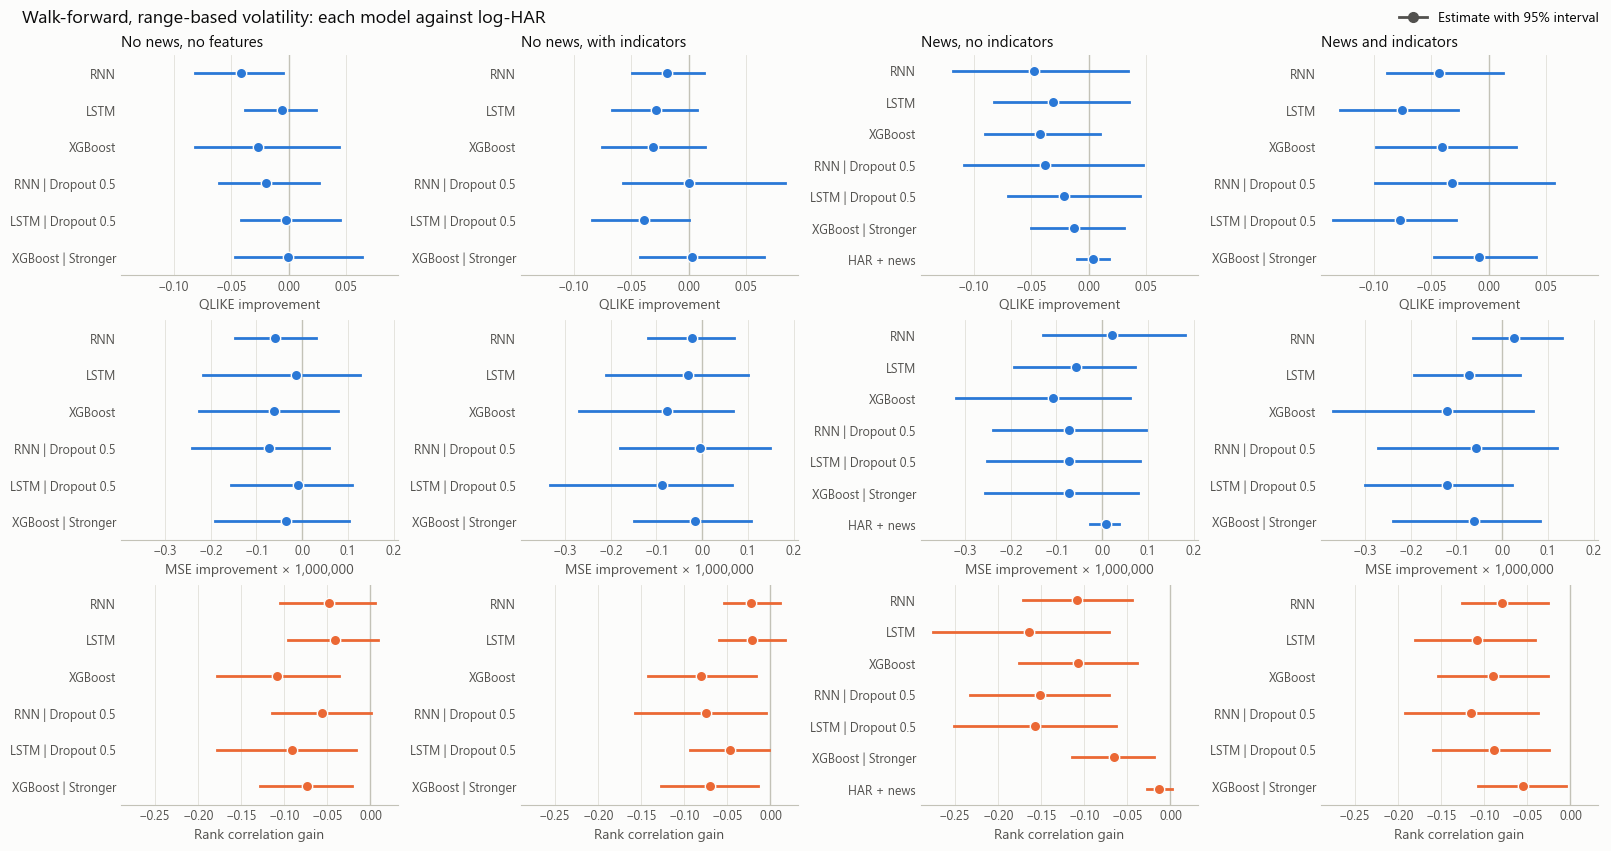

In [9]:
plot_move_comparisons(
    against_har[against_har["model"].isin(trained["model"].unique())],
    "track",
    "Walk-forward, range-based volatility: each model against log-HAR",
    metrics=COMPARISON_METRICS,
)

## Question 3: does news help?

### News against no news: table

The same model on two input sets, compared day by day. Positive differences favor news. MSE is shown multiplied by 1,000,000.

In [10]:
news = compare_news(walk_forward)
news.to_csv(RESULTS_DIR / "range_news_comparisons.csv", index=False)
scale(news).drop(columns="days")

,comparison,model,qlike_first,qlike_second,rank_first,rank_second,qlike_improvement,qlike_improvement_lower,qlike_improvement_upper,mse_improvement,mse_improvement_lower,mse_improvement_upper,rank_gain,rank_gain_lower,rank_gain_upper
0,"News vs no news, no features",RNN,0.5092,0.5031,0.4071,0.4671,-0.0061,-0.0633,0.0583,0.0816,-0.0396,0.2476,-0.0600,-0.0967,-0.0226
1,"News vs no news, no features",LSTM,0.4921,0.4674,0.3521,0.4747,-0.0247,-0.0646,0.0276,-0.0434,-0.1828,0.0845,-0.1227,-0.1899,-0.0608
2,"News vs no news, no features",XGBoost,0.5040,0.4881,0.4090,0.4075,-0.0158,-0.0378,0.0019,-0.0449,-0.1077,0.0042,0.0015,-0.0162,0.0185
3,"News vs no news, no features",RNN | Dropout 0.5,0.4997,0.4813,0.3643,0.4595,-0.0185,-0.0580,0.0249,-0.0000,-0.0819,0.0881,-0.0952,-0.1362,-0.0498
4,"News vs no news, no features",LSTM | Dropout 0.5,0.4828,0.4634,0.3591,0.4253,-0.0193,-0.0410,0.0070,-0.0621,-0.1324,-0.0058,-0.0662,-0.1109,-0.0149
5,"News vs no news, no features",XGBoost | Stronger,0.4741,0.4623,0.4500,0.4418,-0.0118,-0.0355,0.0043,-0.0373,-0.0917,0.0053,0.0082,-0.0053,0.0227
6,News + indicators vs indicators,RNN,0.5047,0.4806,0.4360,0.4927,-0.0241,-0.0535,0.0098,0.0491,-0.0146,0.1180,-0.0567,-0.0916,-0.0176
7,News + indicators vs indicators,LSTM,0.5371,0.4898,0.4077,0.4938,-0.0472,-0.0737,-0.0225,-0.0407,-0.1716,0.0682,-0.0861,-0.1486,-0.0386
8,News + indicators vs indicators,XGBoost,0.5020,0.4928,0.4256,0.4352,-0.0092,-0.0316,0.0140,-0.0426,-0.1071,0.0076,-0.0096,-0.0284,0.0138
9,News + indicators vs indicators,RNN | Dropout 0.5,0.4936,0.4609,0.4003,0.4412,-0.0327,-0.0542,-0.0117,-0.0534,-0.1244,0.0151,-0.0409,-0.0758,-0.0021


### News against no news: chart

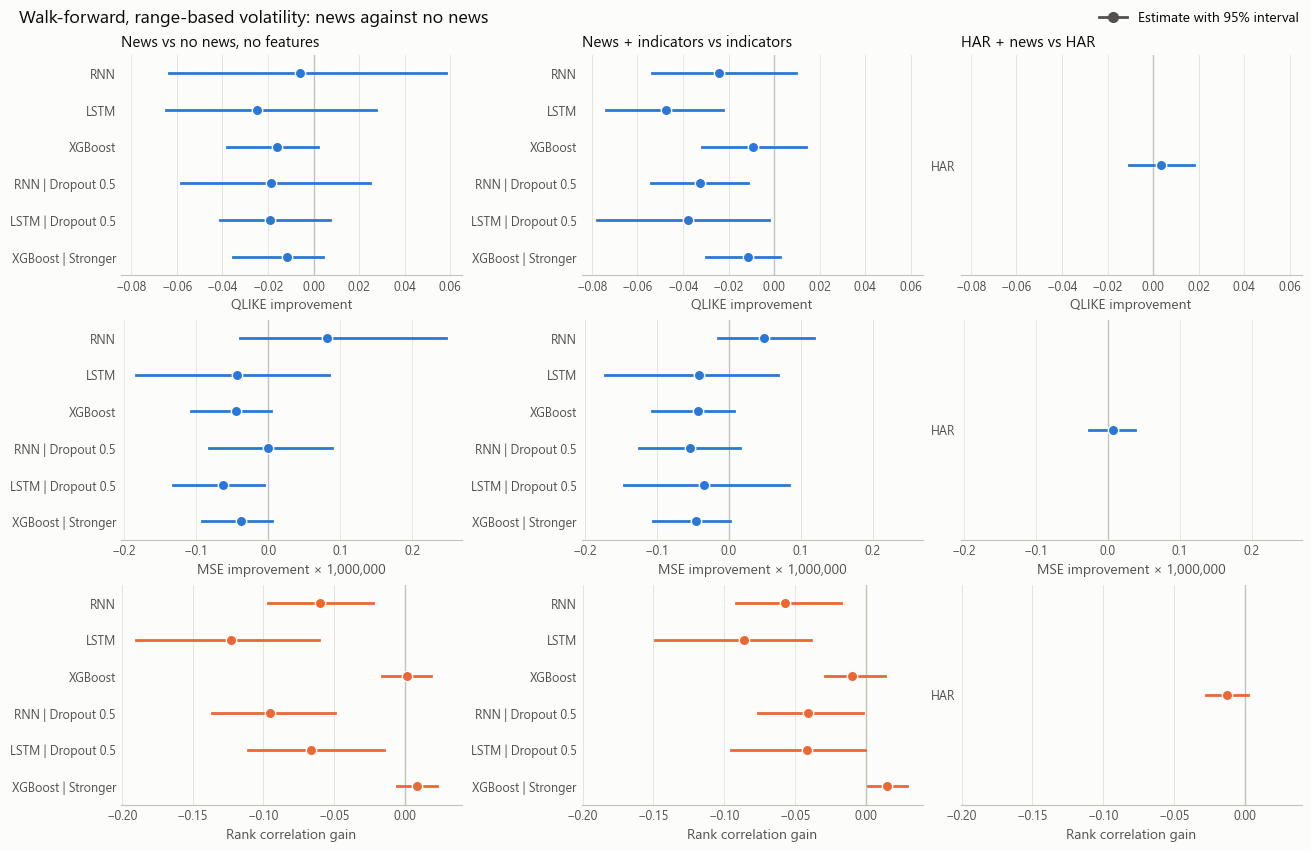

In [11]:
plot_move_comparisons(news, "comparison", "Walk-forward, range-based volatility: news against no news", metrics=COMPARISON_METRICS)

## Price bands

### Price bands: coverage and width

Each forecast becomes a band of previous close × exp(±1.96 σ). A 95% band should contain about 95% of next-day closes, and returns have more extreme days than a normal distribution, so expect a little less. At the same coverage, narrower is better. `average_width` is the band's full width as a share of the price. The train-mean band has the same width every round.

In [12]:
band_scores(walk_forward).sort_values("average_width")

,track,model,coverage,average_width,baseline_coverage,baseline_average_width
24,news_with_feature_engineering_and_tech,LSTM | Dropout 0.5,0.9155,0.1112,0.9475,0.1328
11,no_news_with_feature_engineering,LSTM | Dropout 0.5,0.9245,0.1130,0.9475,0.1328
15,news_with_feature_engineering,XGBoost,0.9232,0.1130,0.9475,0.1328
22,news_with_feature_engineering_and_tech,XGBoost,0.9270,0.1131,0.9475,0.1328
21,news_with_feature_engineering_and_tech,LSTM,0.9155,0.1134,0.9475,0.1328
9,no_news_with_feature_engineering,XGBoost,0.9270,0.1139,0.9475,0.1328
2,no_news_no_feature_engineering,XGBoost,0.9309,0.1141,0.9475,0.1328
23,news_with_feature_engineering_and_tech,RNN | Dropout 0.5,0.9296,0.1143,0.9475,0.1328
26,no_news_no_feature_engineering,Yesterday,0.8860,0.1144,0.9475,0.1328
25,news_with_feature_engineering_and_tech,XGBoost | Stronger,0.9347,0.1153,0.9475,0.1328


### Price bands: log-HAR, all scored days

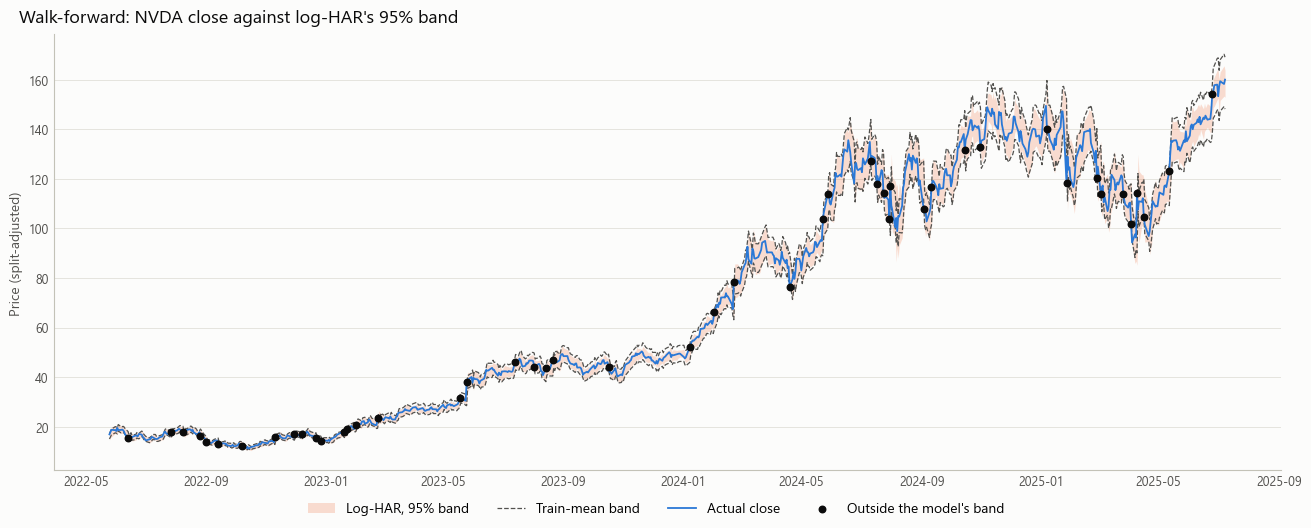

In [13]:
har_bands = price_bands(walk_forward, NO_NEWS_NO_FEATURES, "HAR")
plot_price_bands(har_bands, "Log-HAR", title="Walk-forward: NVDA close against log-HAR's 95% band")

### Price bands: log-HAR, last 120 scored days

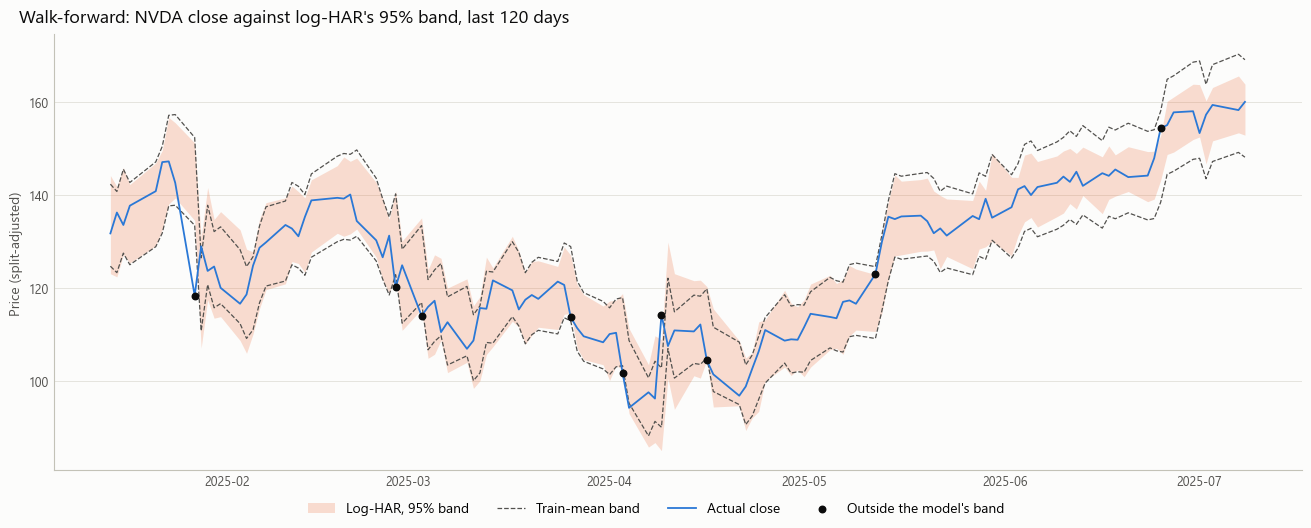

In [14]:
plot_price_bands(har_bands, "Log-HAR", days=120, title="Walk-forward: NVDA close against log-HAR's 95% band, last 120 days")

### Price bands: largest misses

The days the close fell furthest outside log-HAR's band. `miss_size` is the move divided by the band's half-width. Earnings dates aren't in the data, so these are for checking by hand.

In [15]:
largest_misses(har_bands)

,day,previous_close,close,move,lower,upper,miss_size
251,2023-05-25,30.5210,37.9590,0.2181,29.0847,32.0282,4.5246
669,2025-01-27,142.6200,118.4200,-0.1859,134.5454,151.1792,3.1905
437,2024-02-22,67.4529,78.5158,0.1519,63.5827,71.5586,2.5703
75,2022-09-13,14.4907,13.1180,-0.0995,13.8226,15.1911,2.1083
187,2023-02-23,20.7390,23.6470,0.1312,19.4659,22.0953,2.0713
501,2024-05-23,94.9276,103.7740,0.0891,90.7123,99.3387,1.9617
477,2024-04-19,84.6510,76.1820,-0.1054,79.7636,89.8379,1.7725
117,2022-11-10,13.7627,15.7346,0.1339,12.7247,14.8854,1.7075
130,2022-11-30,15.6236,16.9106,0.0792,14.8623,16.4239,1.5846
64,2022-08-26,17.8901,16.2392,-0.0968,16.7855,19.0674,1.5192


## 80/10/10 split

### 80/10/10: chart

The 123 validation days, which aren't used for early stopping.

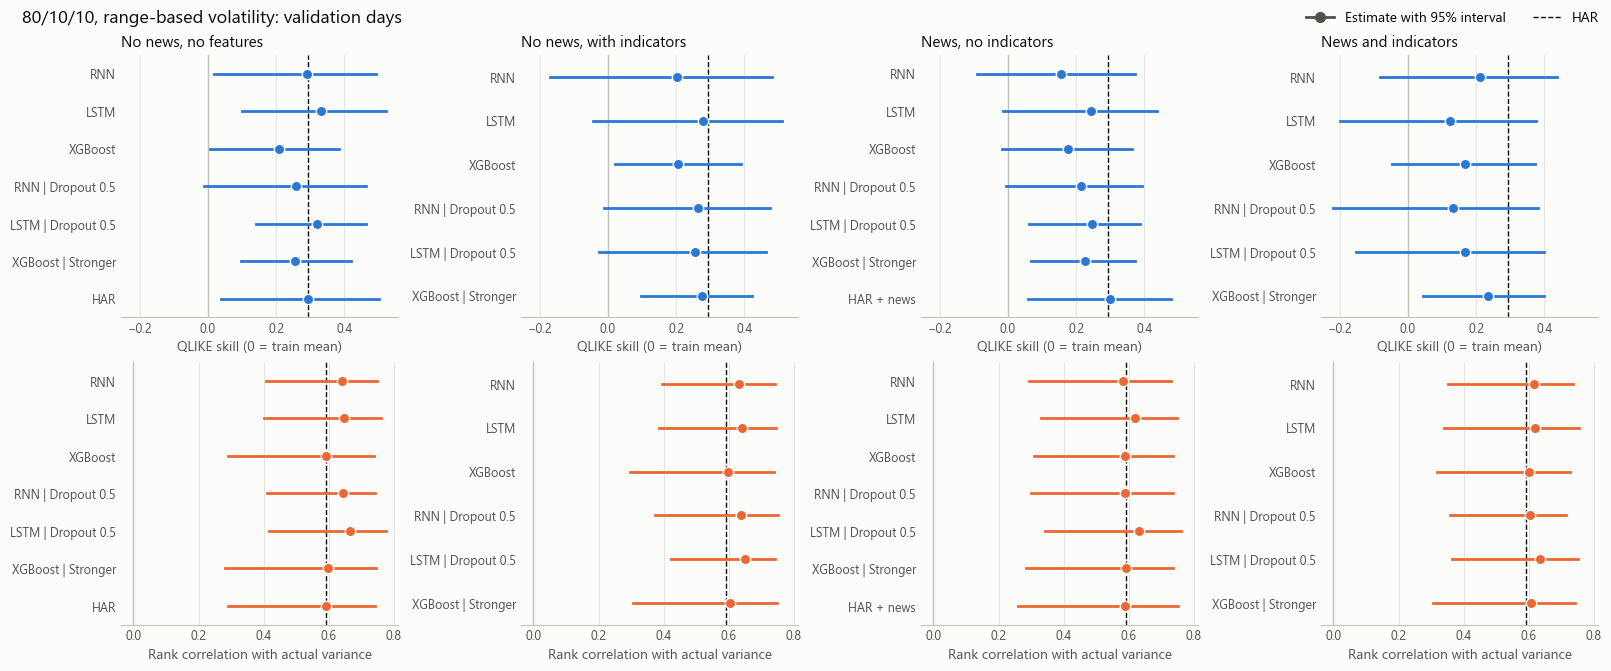

In [16]:
split_intervals = range_intervals(validation)
plot_move_intervals(split_intervals, title="80/10/10, range-based volatility: validation days", metrics=INTERVAL_METRICS)

### 80/10/10: table

In [17]:
split_intervals.drop(columns="days").sort_values("qlike_skill", ascending=False)

,track,model,qlike,baseline_qlike,correlation,qlike_skill,qlike_skill_lower,qlike_skill_upper,oos_r2,oos_r2_lower,oos_r2_upper,rank_correlation,rank_correlation_lower,rank_correlation_upper
1,no_news_no_feature_engineering,LSTM,0.4822,0.7199,0.3723,0.3302,0.0986,0.5214,0.1478,0.0092,0.3484,0.6481,0.4004,0.7599
4,no_news_no_feature_engineering,LSTM | Dropout 0.5,0.4888,0.7199,0.3792,0.3210,0.1411,0.4640,0.1205,0.0312,0.3063,0.6661,0.4162,0.7758
19,news_with_feature_engineering,HAR + news,0.5042,0.7199,0.3551,0.2996,0.0583,0.4781,0.1225,0.0128,0.2917,0.5876,0.2605,0.7504
6,no_news_no_feature_engineering,HAR,0.5092,0.7199,0.3518,0.2927,0.0381,0.5025,0.1289,0.0074,0.3148,0.5915,0.2919,0.7433
0,no_news_no_feature_engineering,RNN,0.5105,0.7199,0.3320,0.2909,0.0165,0.4913,0.1116,-0.0247,0.2935,0.6403,0.4073,0.7477
8,no_news_with_feature_engineering,LSTM,0.5201,0.7199,0.3384,0.2775,-0.0432,0.5102,0.1246,-0.0134,0.3142,0.6418,0.3870,0.7450
12,no_news_with_feature_engineering,XGBoost | Stronger,0.5224,0.7199,0.3184,0.2743,0.0975,0.4211,0.0839,0.0166,0.2116,0.6040,0.3046,0.7483
10,no_news_with_feature_engineering,RNN | Dropout 0.5,0.5300,0.7199,0.3868,0.2638,-0.0106,0.4743,0.1219,0.0023,0.2972,0.6382,0.3744,0.7510
3,no_news_no_feature_engineering,RNN | Dropout 0.5,0.5341,0.7199,0.3481,0.2581,-0.0128,0.4638,0.0974,-0.0020,0.2664,0.6435,0.4108,0.7440
11,no_news_with_feature_engineering,LSTM | Dropout 0.5,0.5361,0.7199,0.3536,0.2553,-0.0251,0.4642,0.1050,0.0053,0.3144,0.6513,0.4240,0.7428


### 80/10/10: news against no news

Positive differences favor news. MSE is shown multiplied by 1,000,000.

In [18]:
scale(compare_news(validation)).drop(columns="days")

,comparison,model,qlike_first,qlike_second,rank_first,rank_second,qlike_improvement,qlike_improvement_lower,qlike_improvement_upper,mse_improvement,mse_improvement_lower,mse_improvement_upper,rank_gain,rank_gain_lower,rank_gain_upper
0,"News vs no news, no features",RNN,0.6085,0.5105,0.5826,0.6403,-0.0980,-0.2061,-0.0020,-0.2351,-0.7925,0.1539,-0.0577,-0.1386,0.0158
1,"News vs no news, no features",LSTM,0.5448,0.4822,0.6186,0.6481,-0.0626,-0.1278,0.0058,-0.4387,-1.2094,0.0257,-0.0295,-0.1092,0.0243
2,"News vs no news, no features",XGBoost,0.5926,0.5694,0.5902,0.5922,-0.0231,-0.0593,0.0089,-0.0430,-0.1659,0.0508,-0.0021,-0.0416,0.0341
3,"News vs no news, no features",RNN | Dropout 0.5,0.5659,0.5341,0.5889,0.6435,-0.0318,-0.1042,0.0232,-0.1446,-0.4933,0.1350,-0.0546,-0.1404,0.0254
4,"News vs no news, no features",LSTM | Dropout 0.5,0.5424,0.4888,0.6328,0.6661,-0.0536,-0.1068,-0.0018,-0.2460,-0.6082,-0.0070,-0.0333,-0.1196,0.0202
5,"News vs no news, no features",XGBoost | Stronger,0.5575,0.5369,0.5919,0.5968,-0.0206,-0.0432,-0.0001,-0.0697,-0.1819,0.0174,-0.0049,-0.0249,0.0115
6,News + indicators vs indicators,RNN,0.5673,0.5735,0.6153,0.6325,0.0063,-0.0633,0.0743,0.0251,-0.1853,0.2361,-0.0172,-0.1001,0.0435
7,News + indicators vs indicators,LSTM,0.6320,0.5201,0.6198,0.6418,-0.1119,-0.2251,-0.0040,-0.4495,-1.3742,0.1097,-0.0220,-0.0965,0.0340
8,News + indicators vs indicators,XGBoost,0.5989,0.5721,0.6001,0.5970,-0.0268,-0.0694,0.0150,-0.1053,-0.2335,0.0066,0.0031,-0.0227,0.0386
9,News + indicators vs indicators,RNN | Dropout 0.5,0.6251,0.5300,0.6041,0.6382,-0.0951,-0.1820,-0.0133,-0.2537,-0.5832,0.0028,-0.0341,-0.0759,0.0149


## Conclusions

Walk-forward is the evidence that counts. "Clearly" means the 95% interval is entirely on one side of zero.

**Question 1: no, not by the fixed rule.** Log-HAR's QLIKE improvement over the train mean is 0.066 (−0.066 to 0.181), and its MSE improvement interval also includes zero. No model has a QLIKE interval above zero. By the rule fixed in advance, news isn't tested on this target. The news results above are shown for completeness and don't count as a test.

This is not the same failure as the move-size test:

- **The forecasts rank days well.** Log-HAR's rank correlation with the actual variance is 0.52 (0.40 to 0.59), against 0.13 for the move-size target.
- **A few shocks swamp the average.** One day, 2023-05-25, the +22% earnings jump, is about a quarter of log-HAR's total QLIKE. The 8 largest days are 42% of it.
- **Without those 8 days (1%), log-HAR clearly beats the train mean** on QLIKE (0.107, 0.051 to 0.171), MSE and rank correlation.
- **On the 80/10/10 validation days,** which have no shock that large, log-HAR's QLIKE skill is 0.29 (0.04 to 0.50).

So the forecasts carry real information on ordinary days, but nothing in the inputs warns of the biggest jumps. From memory, not from the data: at least 4 of the 8 days were NVDA earnings, and others include the August 2024 sell-off, the DeepSeek drop and the April 2025 tariff swings. Earnings dates are known in advance, which is why an earnings-date input is the obvious next step.

**Question 2: no.** No trained model clearly beats log-HAR on QLIKE or MSE. 3 of 24 are clearly worse on QLIKE, and 18 of 24 are clearly worse on rank correlation. The simple 5-day, 20-day and yesterday baselines are all clearly worse than log-HAR on QLIKE.

**Question 3 (not a test, see question 1): no sign that news helps.** No news comparison is clearly better on QLIKE or MSE. 3 of 13 are clearly worse on QLIKE, 1 on MSE, and 8 of 13 on rank correlation. Log-HAR + news is level with log-HAR (QLIKE +0.003, −0.011 to 0.018). On 80/10/10, news is never clearly better and is clearly worse on QLIKE in 5 of 13.

**Price bands.** Log-HAR's band contains 93.9% of next-day closes, and is 12.2% of the price wide on average. The train-mean band contains 94.8% and is 13.3% wide. So log-HAR's band is about 8% narrower and misses about 1 more day in 100. The bands visibly widen in calm-to-rough changes, such as April 2025, but the largest misses are the same earnings and shock days.